In [1]:
print("Hello, Dora!")

Hello, Dora!


In [1]:
from pathlib import Path
import pandas as pd

files = sorted(Path.cwd().glob("20260619-London-listings*.gz"))

if len(files) == 1:
    print("File found:", files[0].name)
    preview = pd.read_csv(files[0], compression="gzip", nrows=5)
    display(preview[["id", "neighbourhood_cleansed", "room_type"]])
else:
    print("Current directory:", Path.cwd())
    print("Matching files:", [file.name for file in files])

File found: 20260619-London-listings.csv.gz


,id,neighbourhood_cleansed,room_type
0,264776,Lewisham,Entire home/apt
1,264777,Lewisham,Entire home/apt
2,264778,Lewisham,Entire home/apt
3,264779,Lewisham,Entire home/apt
4,264780,Lewisham,Entire home/apt


In [2]:
listings = pd.read_csv(
    "20260619-London-listings.csv.gz",
    usecols=["id", "neighbourhood_cleansed", "room_type"],
    dtype={"id": "string"}
)

print("Unique listing IDs:", listings["id"].nunique())
print("Boroughs covered:", listings["neighbourhood_cleansed"].nunique())

Unique listing IDs: 96651
Boroughs covered: 33


In [3]:
entire_homes = listings.loc[listings["room_type"] == "Entire home/apt"]
print("Entire-home listings:", entire_homes["id"].nunique())
print("Boroughs with entire-home listings:", entire_homes["neighbourhood_cleansed"].nunique())

Entire-home listings: 62456
Boroughs with entire-home listings: 33


In [4]:
borough_counts = (
    entire_homes.groupby("neighbourhood_cleansed")["id"]
    .nunique()
    .reset_index(name="entire_listings")
    .sort_values("entire_listings", ascending=False)
)

display(borough_counts.head(5))
print("Total across boroughs:", borough_counts["entire_listings"].sum())

,neighbourhood_cleansed,entire_listings
32,Westminster,9130
19,Kensington and Chelsea,5371
5,Camden,4565
29,Tower Hamlets,4401
11,Hackney,4075


Total across boroughs: 62456


In [5]:
previous = pd.read_csv("Borough_counts.csv").rename(
    columns={"entire_listings": "previous_count"}
)

check = borough_counts.rename(columns={"neighbourhood_cleansed": "NAME"}).merge(
    previous[["NAME", "previous_count"]],
    on="NAME",
    how="outer",
    validate="one_to_one"
)

differences = check[check["entire_listings"] != check["previous_count"]]
print("Boroughs checked:", len(check))
print("Boroughs with discrepancies:", len(differences))
display(differences)

Boroughs checked: 33
Boroughs with discrepancies: 0


,NAME,entire_listings,previous_count


In [6]:
borough_rates = check[["NAME", "entire_listings"]].merge(
    previous[["NAME", "GSS_CODE", "dwellings_2025"]],
    on="NAME",
    validate="one_to_one"
)

borough_rates["entire_per_1000"] = (
    borough_rates["entire_listings"] / borough_rates["dwellings_2025"] * 1000
)

top_five = borough_rates.nlargest(5, "entire_per_1000")
display(top_five[["NAME", "entire_listings", "dwellings_2025", "entire_per_1000"]].round(2))

,NAME,entire_listings,dwellings_2025,entire_per_1000
32,Westminster,9130,133518,68.38
6,City of London,500,7770,64.35
19,Kensington and Chelsea,5371,90344,59.45
5,Camden,4565,110736,41.22
11,Hackney,4075,119903,33.99


In [7]:
columns = pd.read_csv("20260619-London-listings.csv.gz", nrows=0).columns
print("number_of_reviews_ltm" in columns)

True


In [8]:
review_data = pd.read_csv(
    "20260619-London-listings.csv.gz",
    usecols=["id", "neighbourhood_cleansed", "room_type", "number_of_reviews_ltm"],
    dtype={"id": "string"}
)

reviewed_homes = review_data.loc[
    (review_data["room_type"] == "Entire home/apt")
    & (review_data["number_of_reviews_ltm"] >= 1)
]

print("Entire-home listings reviewed in the past 12 months:", reviewed_homes["id"].nunique())

Entire-home listings reviewed in the past 12 months: 33861


In [9]:
reviewed_counts = reviewed_homes.groupby("neighbourhood_cleansed")["id"].nunique()

comparison = borough_rates.copy()
comparison["reviewed_listings"] = comparison["NAME"].map(reviewed_counts).fillna(0).astype(int)
comparison["reviewed_per_1000"] = (
    comparison["reviewed_listings"] / comparison["dwellings_2025"] * 1000
)

comparison["rank_all"] = comparison["entire_per_1000"].rank(ascending=False, method="min").astype(int)
comparison["rank_reviewed"] = comparison["reviewed_per_1000"].rank(ascending=False, method="min").astype(int)

display_columns = ["NAME", "rank_all", "rank_reviewed", "reviewed_per_1000"]
display(comparison.sort_values("rank_reviewed")[display_columns].head(5).round(2))
display(comparison.loc[comparison["NAME"] == "City of London", display_columns].round(2))

,NAME,rank_all,rank_reviewed,reviewed_per_1000
32,Westminster,1,1,41.33
6,City of London,2,2,34.11
19,Kensington and Chelsea,3,3,33.34
5,Camden,4,4,24.66
18,Islington,6,5,17.15


,NAME,rank_all,rank_reviewed,reviewed_per_1000
6,City of London,2,2,34.11


In [12]:
import geopandas as gpd
boundaries = gpd.read_file("London_boroughs.gpkg")
print(len(boundaries), boundaries.columns.tolist())

33 ['GSS_CODE', 'NAME', 'entire_listings', 'dwellings_2025', 'entire_per_1000', 'geometry']


In [11]:
%pip install geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.7/24.7 MB 1.2 MB/s  0:00:20m0:00:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 874.0 kB/s  0:00:05 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 476.9 kB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [geopandas]/4 [pyogrio]
Note: you may need to restart the kernel to use updated packages.


In [13]:
map_data = boundaries[["GSS_CODE", "geometry"]].merge(
    comparison,
    on="GSS_CODE",
    how="left",
    validate="one_to_one"
)

print("Boroughs on the map:", len(map_data))
print("Boroughs matched to the recent-review measure:", map_data["reviewed_per_1000"].notna().sum())

Boroughs on the map: 33
Boroughs matched to the recent-review measure: 33


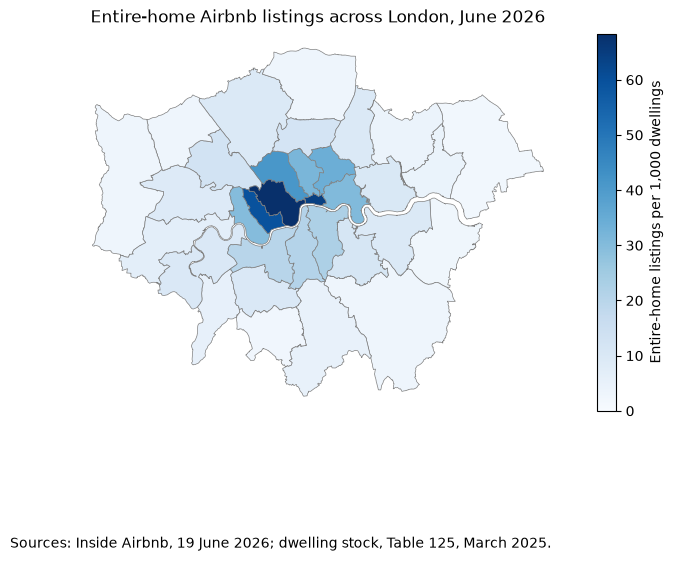

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))

map_data.plot(
    ax=ax,
    column="entire_per_1000",
    cmap="Blues",
    vmin=0,
    edgecolor="grey",
    linewidth=0.5,
    legend=True,
    legend_kwds={"label": "Entire-home listings per 1,000 dwellings", "shrink": 0.7}
)

ax.set_title("Entire-home Airbnb listings across London, June 2026")
ax.set_axis_off()
fig.text(0.05, 0.03, "Sources: Inside Airbnb, 19 June 2026; dwelling stock, Table 125, March 2025.")
plt.show()